In [ ]:
from google.colab import drive
import os, subprocess

drive.mount("/content/drive")

work = "/content/drive/MyDrive/computer_vision"
os.chdir(work)

data_dir = "/root/crack-detect/data"
if not os.path.exists(data_dir + "/Bridge_Crack_Image"):
    os.makedirs(data_dir, exist_ok=True)
    subprocess.run(["unzip", "-q", work + "/archive.zip", "Bridge_Crack_Image/*", "-d", data_dir], check=True)

print(os.getcwd(), os.listdir(data_dir))

Mounted at /content/drive
/content/drive/MyDrive/computer_vision ['Bridge_Crack_Image']


In [ ]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

root = Path.home() / "crack-detect" / "data" / "Bridge_Crack_Image" / "DBCC_Training_Data_Set"

rows = []
for split in ["train", "val"]:
    for p in (root / split).iterdir():
        if p.suffix.lower() == ".jpeg":
            rows.append({"path": str(p), "label": int(p.name.lower().startswith("crack")), "split": split})

df = pd.DataFrame(rows)
print(df.path.map(lambda s: Path(s).stem.rstrip("0123456789")).value_counts())

path
no       48000
crack     7000
Name: count, dtype: int64


In [ ]:
train_idx = df[df.split == "train"].index
_, test_idx = train_test_split(train_idx, test_size=0.1, stratify=df.loc[train_idx, "label"], random_state=42)
df.loc[test_idx, "split"] = "test"

df.to_csv("manifest.csv", index=False)
print(df.groupby(["split", "label"]).size().unstack(fill_value=0))

label      0     1
split             
test    4400   600
train  39600  5400
val     4000  1000


(16, 16)    200
Name: count, dtype: int64


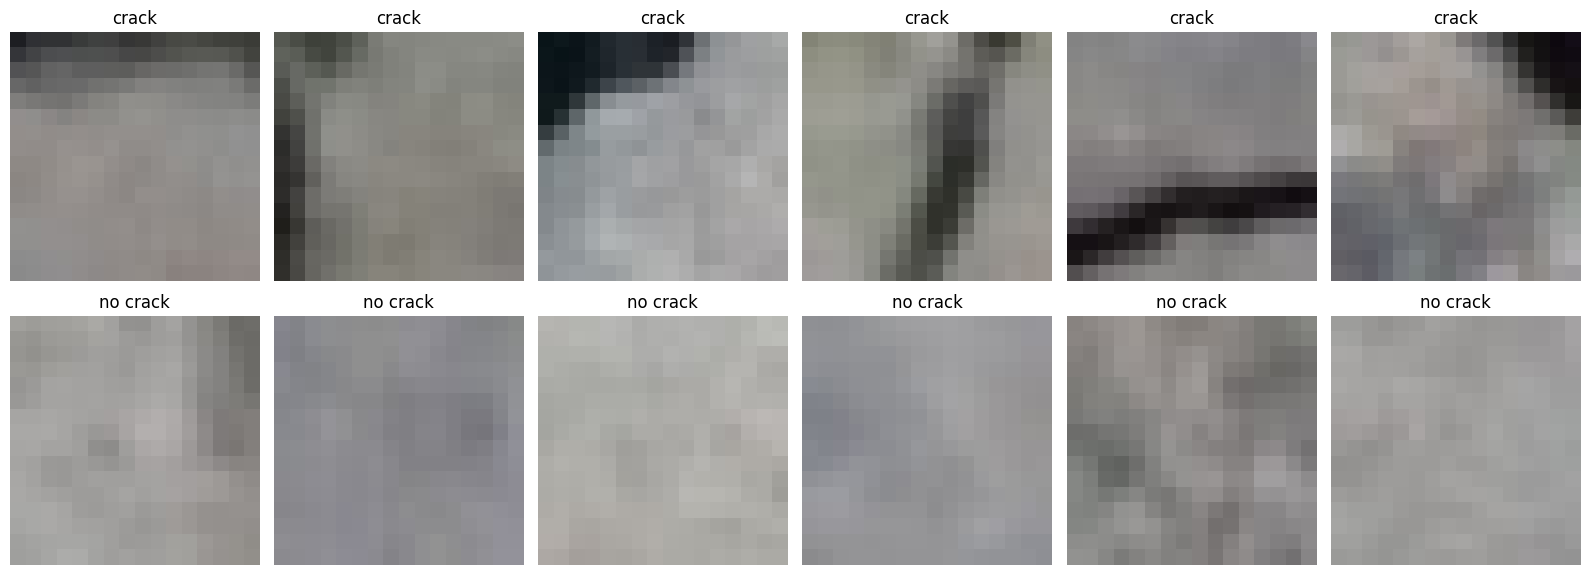

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

sizes = [Image.open(p).size for p in df.sample(200, random_state=0).path]
print(pd.Series(sizes).value_counts().head())

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for r, lab in enumerate([1, 0]):
    sample = df[df.label == lab].sample(6, random_state=1)
    for ax, p in zip(axes[r], sample.path):
        ax.imshow(Image.open(p).convert("RGB"))
        ax.set_title("crack" if lab else "no crack")
        ax.axis("off")
plt.tight_layout()
plt.show()